# neural network

Same data, features, folds and per-fold processing as `train.ipynb`
(sections 1--3 below are copied from it unchanged), so the results are
directly comparable with Random Forest / XGBoost / CatBoost there.

A neural network needs three extra steps that tree models don't. All of
them are fitted on each fold's **training rows only**:

- **Numeric scaling** -- each numeric input standardised to mean 0, std 1.
- **Category embeddings** -- each categorical feature gets a small learned
  vector per category instead of an arbitrary integer code.
- **Target on log scale** -- the network predicts standardised log(price);
  predictions are converted back to dollars with Duan's smearing factor.

Training stops early using a **time-ordered validation slice**: the last
10% of each fold's training period. The fold's test period is never used
for training or for choosing when to stop.

In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/remake_dataset.parquet")

# TimeSeriesSplit assumes row order IS time order -- sort explicitly rather
# than relying on the order the parquet was written in.
df = df.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Date range: {df['sale_date_parsed'].min().date()} to {df['sale_date_parsed'].max().date()}")

Loaded 59,708 rows, 33 columns
Date range: 2024-01-01 to 2026-08-18


## 1. Feature groups

In [19]:
ID_COLS = ["valuation_id_concat", "sale_id", "sale_date_parsed"]
TARGET = "sale_price_gross"

CAT_COLS = [
    "property_type", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "noise_category_combination",
]
BOOL_COLS = ["in_flood_plain"]
NUM_COLS = [
    # property
    "land_area", "building_total_floor_area",
    "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
    # location / spatial
    "latitude", "longitude", "distance_to_cbd", "walk_supermarket_network_m",
    "walk_bus_stop_network_m", "distance_to_school", "area_level_deprivation_index",
    # socioeconomic
    "median_personal_income_by_sa", "employment_rate_by_sa", "unemployment_rate_by_sa",
    "population_counts_by_sa", "population_density",
    # environment
    "distance_to_coastline",
    # market / time
    "building_consents", "sale_year", "sale_month",
]
FEATURE_COLS = CAT_COLS + BOOL_COLS + NUM_COLS

# Near-duplicates dropped after feature_reduction.ipynb (set C):
# sale_quarter is calculated from sale_month, and mass_total_floor_area repeats
# building_total_floor_area (rho 0.96). Dropping both cost under 0.5% RMSE.
DROPPED_COLS = ["sale_quarter", "mass_total_floor_area"]

unassigned = set(df.columns) - set(FEATURE_COLS) - set(ID_COLS) - {TARGET} - set(DROPPED_COLS)
missing = set(FEATURE_COLS) - set(df.columns)
assert not unassigned, f"Columns not assigned to any group: {unassigned}"
assert not missing, f"Feature columns not in dataset: {missing}"

print(f"{len(FEATURE_COLS)} features: {len(CAT_COLS)} categorical, {len(BOOL_COLS)} boolean, {len(NUM_COLS)} numeric")

27 features: 5 categorical, 1 boolean, 21 numeric


## 2. Per-fold processing (same as `train.ipynb` section 3)

Category encoding, bool to int, median fill and the 1st/99th-percentile
price trim -- all learned from the training rows of each fold.

In [20]:
def prepare_fold(train_df, test_df):
    """Encode, impute and price-trim one fold. Returns X/y for train and test."""
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[CAT_COLS])

    X_train = train_df[FEATURE_COLS].copy()
    X_test = test_df[FEATURE_COLS].copy()
    X_train[CAT_COLS] = encoder.transform(train_df[CAT_COLS])
    X_test[CAT_COLS] = encoder.transform(test_df[CAT_COLS])
    for col in BOOL_COLS:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    nan_cols = [c for c in NUM_COLS if X_train[c].isna().any() or X_test[c].isna().any()]
    train_medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(train_medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(train_medians)

    y_train = train_df[TARGET].values
    y_test = test_df[TARGET].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    return {
        "X_train": X_train[train_keep], "y_train": y_train[train_keep],
        "X_test": X_test[test_keep], "y_test": y_test[test_keep],
        "test_idx": test_df.index[test_keep], "price_limits": (p1, p99),
    }

## 3. Build the 5 folds

In [21]:
kf = TimeSeriesSplit(n_splits=5)
folds = []
rows = []
for fold_i, (train_idx, test_idx) in enumerate(kf.split(df), start=1):
    f = prepare_fold(df.iloc[train_idx], df.iloc[test_idx])
    assert not f["X_train"].isna().any().any() and not f["X_test"].isna().any().any()
    folds.append(f)
    rows.append({
        "fold": fold_i,
        "train_period_end": df.iloc[train_idx]["sale_date_parsed"].max().date(),
        "test_period": f"{df.iloc[test_idx]['sale_date_parsed'].min().date()} to {df.iloc[test_idx]['sale_date_parsed'].max().date()}",
        "n_train": len(f["y_train"]), "n_test": len(f["y_test"]),
        "price_p1": f["price_limits"][0], "price_p99": f["price_limits"][1],
    })

fold_summary = pd.DataFrame(rows).set_index("fold")
print(f"Total test rows across folds: {fold_summary['n_test'].sum():,}")
fold_summary

Total test rows across folds: 48,777


,train_period_end,test_period,n_train,n_test,price_p1,price_p99
fold,,,,,,
1,2024-06-19,2024-06-19 to 2024-11-07,9760,9779,450000.0,4512000.0
2,2024-11-07,2024-11-07 to 2025-04-01,19505,9685,450000.0,4229700.0
3,2025-04-01,2025-04-01 to 2025-08-22,29263,9783,430000.0,4261500.0
4,2025-08-22,2025-08-22 to 2026-01-24,39008,9761,433089.1,4219250.0
5,2026-01-24,2026-01-24 to 2026-08-18,48774,9769,430243.6,4200000.0


## 4. Neural-network inputs

On top of `prepare_fold()`:

- Categorical codes are shifted by +1, so the encoder's "unseen category"
  code (-1) becomes index 0 -- its own embedding row.
- Numeric and boolean columns are **capped at the training 0.5th / 99.5th
  percentiles**, then standardised with the training mean and std.
- The target is log(price), standardised with the training mean/std.
- Predicted prices are **capped at the training price range**.

The two caps matter: unlike trees, a network extends its learned pattern
to rare, extreme input values, and because it predicts log price the
mistake is amplified when converted back to dollars. Without the caps, two
$700K sales with an extreme `building_total_floor_area` were predicted at
~$14.4M, pushing fold 5's RMSE from ~$225K to $301K. Trees can never
predict outside the training price range, so this puts the network on the
same footing.

In [22]:
import time
import torch
from torch import nn

DENSE_COLS = BOOL_COLS + NUM_COLS


def fit_input_transform(X_train):
    """Learn the category ranges, caps and scaling from training rows only."""
    cat_train = X_train[CAT_COLS].to_numpy(dtype=np.int64) + 1
    low = X_train[DENSE_COLS].quantile(0.005)
    high = X_train[DENSE_COLS].quantile(0.995)
    clipped = X_train[DENSE_COLS].clip(low, high, axis=1)
    return {
        "cardinalities": [int(cat_train[:, j].max()) + 1 for j in range(len(CAT_COLS))],
        "low": low, "high": high,
        "mean": clipped.mean(), "std": clipped.std().replace(0, 1),
    }


def encode(t, X):
    """Turn processed feature rows into (category indices, scaled numbers)."""
    # +1 so the encoder's unseen-category code (-1) becomes embedding row 0.
    cat = X[CAT_COLS].to_numpy(dtype=np.int64) + 1
    cat = np.clip(cat, 0, np.array(t["cardinalities"]) - 1)
    dense = X[DENSE_COLS].clip(t["low"], t["high"], axis=1)
    dense = ((dense - t["mean"]) / t["std"]).to_numpy(dtype=np.float32)
    return cat, dense


def nn_inputs(fold):
    t = fit_input_transform(fold["X_train"])
    cat_train, dense_train = encode(t, fold["X_train"])

    log_y = np.log(fold["y_train"])
    y_mean, y_std = log_y.mean(), log_y.std()
    y_train = ((log_y - y_mean) / y_std).astype(np.float32)

    return {
        "transform": t, "cardinalities": t["cardinalities"],
        "cat_train": cat_train, "dense_train": dense_train,
        "y_train": y_train, "y_mean": y_mean, "y_std": y_std,
        "price_range": (fold["y_train"].min(), fold["y_train"].max()),
    }

## 5. Model

A multilayer perceptron with embeddings:

- One embedding per categorical feature, size `min(16, (categories + 1) // 2)`.
- Embeddings concatenated with the scaled numeric inputs, then three hidden
  layers (256 -> 128 -> 64, ReLU, 10% dropout) and one output.
- Adam (learning rate 1e-3), batch size 512, mean-squared-error loss on
  standardised log price, up to 100 epochs, early stopping after 10 epochs
  without validation improvement (best weights restored).

Settings are fixed, not tuned -- the same principle as the tree models.

In [23]:
class PriceNet(nn.Module):
    def __init__(self, cardinalities, n_dense):
        super().__init__()
        self.embeddings = nn.ModuleList(
            nn.Embedding(card, min(16, (card + 1) // 2)) for card in cardinalities
        )
        emb_dim = sum(e.embedding_dim for e in self.embeddings)
        self.mlp = nn.Sequential(
            nn.Linear(emb_dim + n_dense, 256), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, cat, dense):
        emb = [e(cat[:, j]) for j, e in enumerate(self.embeddings)]
        return self.mlp(torch.cat(emb + [dense], dim=1)).squeeze(1)


NN_PARAMS = dict(lr=1e-3, batch_size=512, max_epochs=100, patience=10, val_frac=0.1)


def train_nn(d, seed=42):
    torch.manual_seed(seed)

    # Fold rows are in time order, so the last 10% of training rows is the
    # most recent slice of the training period -- used only for early stopping.
    n = len(d["y_train"])
    n_fit = n - int(n * NN_PARAMS["val_frac"])

    cat = torch.from_numpy(d["cat_train"])
    dense = torch.from_numpy(d["dense_train"])
    y = torch.from_numpy(d["y_train"])
    cat_fit, dense_fit, y_fit = cat[:n_fit], dense[:n_fit], y[:n_fit]
    cat_val, dense_val, y_val = cat[n_fit:], dense[n_fit:], y[n_fit:]

    model = PriceNet(d["cardinalities"], dense.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=NN_PARAMS["lr"])
    loss_fn = nn.MSELoss()

    best_loss, best_state, bad_epochs, epochs_run = np.inf, None, 0, 0
    for epoch in range(NN_PARAMS["max_epochs"]):
        model.train()
        order = torch.randperm(n_fit)
        for start in range(0, n_fit, NN_PARAMS["batch_size"]):
            idx = order[start:start + NN_PARAMS["batch_size"]]
            optimizer.zero_grad()
            loss = loss_fn(model(cat_fit[idx], dense_fit[idx]), y_fit[idx])
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(cat_val, dense_val), y_val).item()
        epochs_run = epoch + 1
        if val_loss < best_loss - 1e-4:
            best_loss, bad_epochs = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= NN_PARAMS["patience"]:
                break

    model.load_state_dict(best_state)
    model.eval()
    return model, epochs_run


def predict_log(model, d, cat, dense):
    with torch.no_grad():
        z = model(torch.from_numpy(cat), torch.from_numpy(dense)).numpy()
    return z * d["y_std"] + d["y_mean"]


def price_predictor(model, d):
    """Return a function: processed feature rows -> predicted price in dollars."""
    # Duan smearing: corrects the downward bias of exp(predicted log price).
    log_actual = d["y_train"] * d["y_std"] + d["y_mean"]
    smear = np.mean(np.exp(log_actual - predict_log(model, d, d["cat_train"], d["dense_train"])))

    def predict(X):
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X, columns=FEATURE_COLS)
        cat, dense = encode(d["transform"], X)
        return np.clip(np.exp(predict_log(model, d, cat, dense)) * smear, *d["price_range"])

    return predict

## 6. Train on the 5 folds

In [24]:
def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))


def mae(y, yhat):
    return np.mean(np.abs(y - yhat))


def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100


start_all = time.time()
nn_preds, fold_rows = [], []
for fold_i, fold in enumerate(folds, start=1):
    start = time.time()
    d = nn_inputs(fold)
    model, epochs_run = train_nn(d)
    pred = price_predictor(model, d)(fold["X_test"])
    nn_preds.append(pred)
    fold_rows.append({
        "fold": fold_i, "epochs": epochs_run, "seconds": round(time.time() - start),
        "RMSE": rmse(fold["y_test"], pred), "MAE": mae(fold["y_test"], pred), "MAPE": mape(fold["y_test"], pred),
    })
    print(f"Fold {fold_i}: {epochs_run} epochs, RMSE ${fold_rows[-1]['RMSE']:,.0f}")

nn_train_seconds = time.time() - start_all
fold_results = pd.DataFrame(fold_rows).set_index("fold")
fold_results.round(2)

Fold 1: 38 epochs, RMSE $275,297
Fold 2: 42 epochs, RMSE $252,247
Fold 3: 28 epochs, RMSE $248,730
Fold 4: 38 epochs, RMSE $234,080
Fold 5: 47 epochs, RMSE $224,206


,epochs,seconds,RMSE,MAE,MAPE
fold,,,,,
1,38,3,275296.57,158945.43,12.84
2,42,7,252246.73,157724.92,13.13
3,28,7,248730.16,147608.76,12.62
4,38,13,234080.10,140193.48,11.55
5,47,19,224205.92,136744.38,11.33


### 6.1 Pooled results (all 5 folds' test predictions combined)

In [25]:
actual = np.concatenate([f["y_test"] for f in folds])
nn_pred = np.concatenate(nn_preds)

results = pd.DataFrame([{
    "model": "NeuralNet",
    "RMSE": rmse(actual, nn_pred), "MAE": mae(actual, nn_pred), "MAPE": mape(actual, nn_pred),
    "train_time_s": nn_train_seconds,
}]).set_index("model")
print(f"Pooled over {len(actual):,} test predictions")
results.round(2)

Pooled over 48,777 test predictions


,RMSE,MAE,MAPE,train_time_s
model,,,,
NeuralNet,247526.09,148230.4,12.29,49.31


## 7. SHAP

A neural network has no tree structure, so `TreeExplainer` doesn't apply.
This uses SHAP's **permutation explainer**, which works for any model: it
swaps feature values in and out with values from a background sample of
training sales and measures how the predicted price changes.

- Same setup as `train.ipynb` section 6: the model is refit on
  **fold 5** and explained on the **same 500 test sales** (same seed).
- 100 background sales drawn from fold 5's training rows.
- Values are in **dollars** (the full prediction, including the log
  back-conversion and caps), so they are on the same scale as the tree
  models' SHAP.

SHAP done in 42s


C:\Users\AD\AppData\Local\Temp\ipykernel_9392\2456506440.py:17: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(nn_shap.values, shap_sample, max_display=20, show=False)


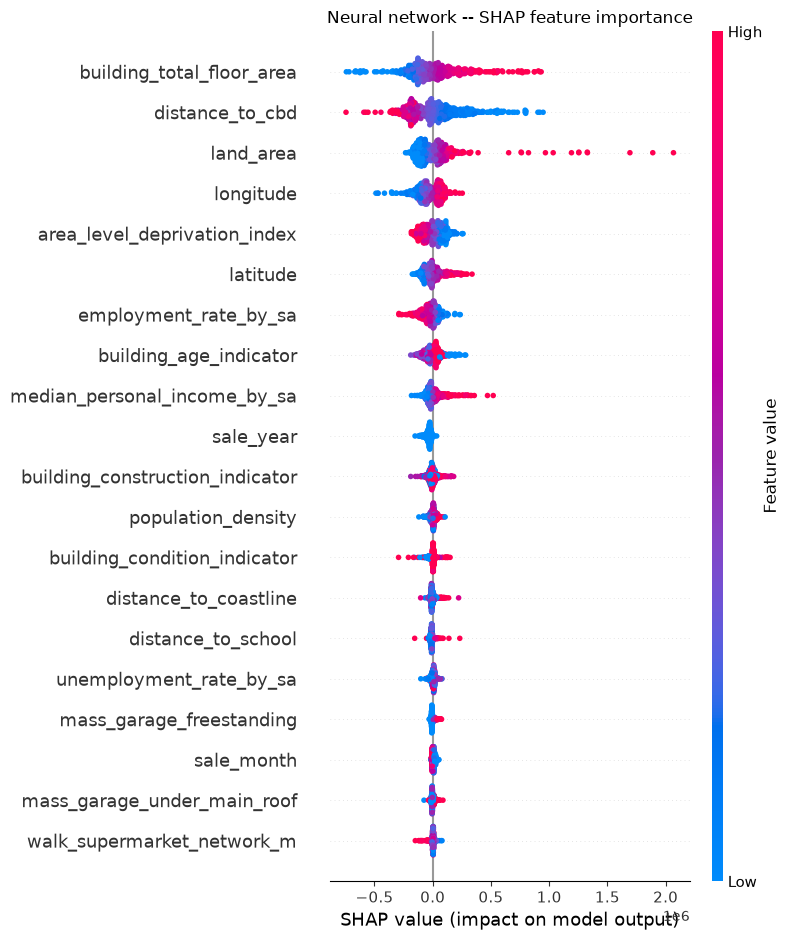

In [26]:
import shap
import matplotlib.pyplot as plt

shap_fold = folds[-1]
shap_sample = shap_fold["X_test"].sample(n=500, random_state=42)  # same 500 sales as train.ipynb
background = shap_fold["X_train"].sample(n=100, random_state=42)

d5 = nn_inputs(shap_fold)
model5, _ = train_nn(d5)
predict5 = price_predictor(model5, d5)

start = time.time()
explainer = shap.PermutationExplainer(predict5, background)
nn_shap = explainer(shap_sample, silent=True)
print(f"SHAP done in {time.time() - start:.0f}s")

shap.summary_plot(nn_shap.values, shap_sample, max_display=20, show=False)
plt.title("Neural network -- SHAP feature importance")
plt.tight_layout()
plt.show()

In [27]:
nn_share = pd.Series(np.abs(nn_shap.values).mean(axis=0), index=FEATURE_COLS)
nn_table = pd.DataFrame({
    "mean |SHAP| ($)": nn_share.round(0),
    "% of total": (nn_share / nn_share.sum() * 100).round(1),
}).sort_values("% of total", ascending=False)
nn_table["rank"] = range(1, len(nn_table) + 1)
nn_table

,mean |SHAP| ($),% of total,rank
building_total_floor_area,178329.0,16.8,1
distance_to_cbd,177027.0,16.6,2
land_area,122272.0,11.5,3
longitude,81582.0,7.7,4
area_level_deprivation_index,74273.0,7.0,5
latitude,62636.0,5.9,6
employment_rate_by_sa,54141.0,5.1,7
building_age_indicator,50314.0,4.7,8
median_personal_income_by_sa,48050.0,4.5,9
sale_year,34012.0,3.2,10


## 8. Explaining one house

Same idea as `train.ipynb` section 7, but for the neural network:
predict one house's price and explain **why** the network gave that price.

- The network is trained on fold 5's training period (sales up to January
  2026); the houses come from fold 5's **test** period, so it has never seen
  them.
- Same 10 houses as `train.ipynb` section 7 (same seed), so the
  network's explanation can be compared with XGBoost's for the same
  property. Set `HOUSE` to pick which one to explain.
- SHAP uses the permutation explainer (as in section 7) with 100 background
  training sales. Values are in dollars and add up exactly:
  `average + contributions = prediction`. The starting "average" is the
  network's mean prediction over the background sales, so it differs a
  little from XGBoost's.

Needs sections 1--6 (data, folds and the network functions); not section 7.

In [28]:
HOUSE = 9  # which house from the table below to explain (1-10)

house_fold = folds[-1]
d_house = nn_inputs(house_fold)
house_model, _ = train_nn(d_house)
predict_house = price_predictor(house_model, d_house)

houses = house_fold["X_test"].sample(n=10, random_state=7)  # same 10 as train.ipynb
house_actual = pd.Series(house_fold["y_test"], index=house_fold["X_test"].index).loc[houses.index]
house_pred = pd.Series(predict_house(houses), index=houses.index)

### 8.1 Readable values and addresses

In [29]:
raw = pd.read_parquet(
    "./cache/dvrs_with_team_external.parquet",
    columns=["valuation_id_concat", "sale_date", "sale_price_gross",
             "situation_number", "additional_situation_number", "situation_name"],
)
raw["sale_price_gross"] = pd.to_numeric(raw["sale_price_gross"], errors="coerce")
raw["sale_date_parsed"] = pd.to_datetime(raw["sale_date"].astype(str).str.zfill(8), format="%d%m%Y")
raw["address"] = (
    raw["situation_number"].astype(str)
    + raw["additional_situation_number"].fillna("").astype(str)
    + " " + raw["situation_name"].fillna("").astype(str).str.title()
)
addresses = (
    raw.drop_duplicates(["valuation_id_concat", "sale_date_parsed", "sale_price_gross"])
    .set_index(["valuation_id_concat", "sale_date_parsed", "sale_price_gross"])["address"]
)
key = pd.MultiIndex.from_frame(df.loc[houses.index, ["valuation_id_concat", "sale_date_parsed", "sale_price_gross"]])
house_address = pd.Series(addresses.reindex(key).values, index=houses.index).fillna("(address not found)")


def readable_row(i):
    """Feature values for one house in human units (from the unprocessed data)."""
    r = df.loc[i]
    age = str(r["building_age_indicator"])
    return {
        "property_type": r["property_type"],
        "building_age_indicator": f"{age}0s" if age.isdigit() else age,
        "building_condition_indicator": r["building_condition_indicator"],
        "building_construction_indicator": r["building_construction_indicator"],
        "noise_category_combination": r["noise_category_combination"].replace("_", " "),
        "in_flood_plain": "yes" if r["in_flood_plain"] else "no",
        "land_area": f"{np.expm1(r['land_area']) * 10_000:,.0f} sqm",  # stored in hectares
        "building_total_floor_area": f"{np.expm1(r['building_total_floor_area']):,.0f} sqm",
        "mass_total_floor_area": f"{np.expm1(r['mass_total_floor_area']):,.0f} sqm",
        "off_street_parking": f"{r['off_street_parking']:.0f}",
        "mass_garage_under_main_roof": f"{r['mass_garage_under_main_roof']:.0f}",
        "mass_garage_freestanding": f"{r['mass_garage_freestanding']:.0f}",
        "latitude": f"{r['latitude']:.4f}",
        "longitude": f"{r['longitude']:.4f}",
        "distance_to_cbd": f"{r['distance_to_cbd'] / 1000:.1f} km",
        "walk_supermarket_network_m": "n/a" if pd.isna(r["walk_supermarket_network_m"]) else f"{np.expm1(r['walk_supermarket_network_m']):,.0f} m",
        "walk_bus_stop_network_m": "n/a" if pd.isna(r["walk_bus_stop_network_m"]) else f"{np.expm1(r['walk_bus_stop_network_m']):,.0f} m",
        "distance_to_school": f"{r['distance_to_school']:,.0f} m",
        "area_level_deprivation_index": f"{r['area_level_deprivation_index']:.0f} of 10",
        "median_personal_income_by_sa": f"${r['median_personal_income_by_sa']:,.0f}",
        "employment_rate_by_sa": f"{r['employment_rate_by_sa']:.0f}%",
        "unemployment_rate_by_sa": f"{r['unemployment_rate_by_sa']:.1f}%",
        "population_counts_by_sa": f"{r['population_counts_by_sa']:,.0f}",
        "population_density": f"{r['population_density']:,.0f} per sq km",
        "distance_to_coastline": f"{r['distance_to_coastline']:,.0f} m",
        "building_consents": f"{r['building_consents']:.0f}",
        "sale_year": f"{r['sale_year']:.0f}",
        "sale_month": f"{r['sale_month']:.0f}",
        "sale_quarter": f"Q{r['sale_quarter']:.0f}",
    }


readable = pd.DataFrame([readable_row(i) for i in houses.index], index=houses.index)[FEATURE_COLS]

### 8.2 The 10 houses at a glance

In [30]:
house_summary = pd.DataFrame({
    "address": house_address,
    "sale_date": df.loc[houses.index, "sale_date_parsed"].dt.date,
    "actual_price": house_actual.map("${:,.0f}".format),
    "predicted_price": house_pred.map("${:,.0f}".format),
    "error": ((house_pred - house_actual) / house_actual * 100).map("{:+.1f}%".format),
})
house_summary.index = range(1, len(house_summary) + 1)
house_summary.index.name = "house"
house_summary

,address,sale_date,actual_price,predicted_price,error
house,,,,,
1,119 Waimumu Rd,2026-05-15,"$1,085,000","$889,716",-18.0%
2,8/3 Park Rise,2026-05-20,"$1,495,000","$1,260,240",-15.7%
3,40E Estuary Rd,2026-02-02,"$690,000","$740,227",+7.3%
4,15A Clifton Rd,2026-05-06,"$2,755,000","$2,937,013",+6.6%
5,182 Glamorgan Dr,2026-04-24,"$835,000","$927,203",+11.0%
6,3 Uma Gr,2026-04-15,"$765,000","$808,033",+5.6%
7,12B Rewi St,2026-06-01,"$1,285,000","$1,348,681",+5.0%
8,10 Pecan Pl,2026-02-19,"$835,000","$985,110",+18.0%
9,10 Wairua Pl,2026-06-21,"$680,000","$666,231",-2.0%


### 8.3 Why the network gave this price

Contributions are grouped into five themes for the summary (a theme's
contribution is the sum of its features'). The waterfall chart shows the 10
largest individual features, the rest combined into one bar; red raises the
price, blue lowers it, and the dotted / solid / dashed lines mark the
average, predicted and actual price.

These explain what the **model** learned from past sales -- they are not
proof that a feature causes a price change in the market.

House 9: 10 Wairua Pl  (sold 2026-06-21)
  Predicted $666,231   actual $680,000   error -2.0%
  Start from the network's average predicted price: $1,140,000
       -$270,672  Location         mainly distance_to_cbd = 40.1 km (-$273,634), latitude = -37.1965 (-$86,460)
       -$116,507  House & land     mainly building_construction_indicator = RI (-$42,258), building_total_floor_area = 129 sqm (-$41,063)
        -$72,026  Neighbourhood    mainly area_level_deprivation_index = 10 of 10 (-$76,575), median_personal_income_by_sa = $39,000 (-$26,251)
        -$18,352  Market & timing  mainly sale_year = 2026 (-$17,825), sale_month = 6 (-$4,030)
         +$3,788  Hazards          mainly in_flood_plain = no (+$2,973), noise_category_combination = outside current overlay (+$815)
  = predicted $666,231
  In short: the biggest push UP is longitude (174.8879, +$47,646); the biggest push DOWN is distance_to_cbd (40.1 km, -$273,634).


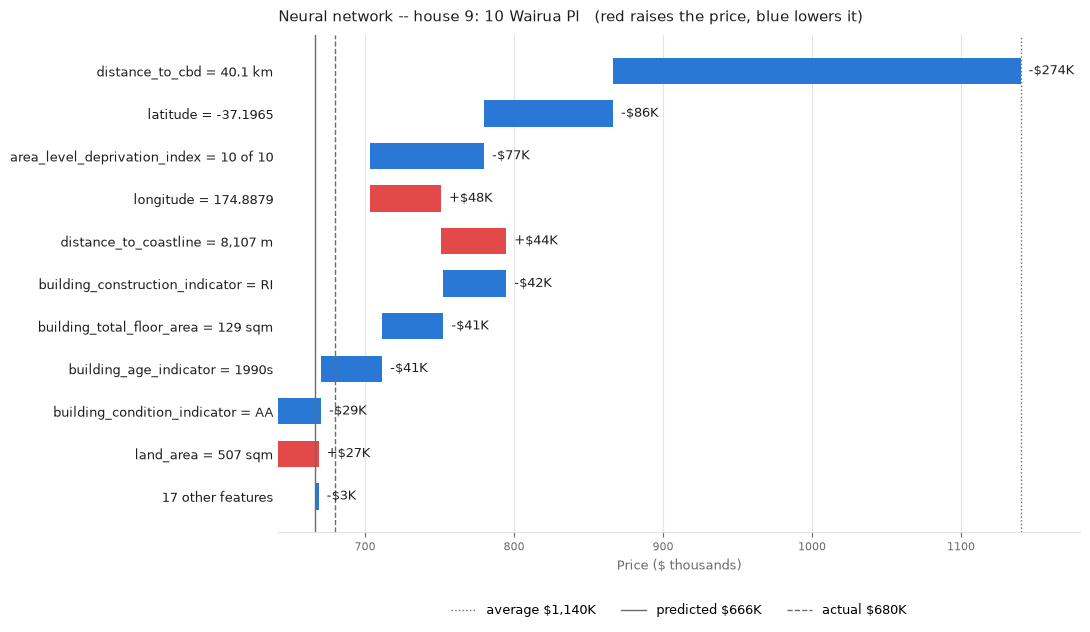

In [31]:
import shap
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

THEMES = {
    "Location": ["latitude", "longitude", "distance_to_cbd", "distance_to_coastline",
                 "distance_to_school", "walk_supermarket_network_m", "walk_bus_stop_network_m"],
    "Neighbourhood": ["area_level_deprivation_index", "median_personal_income_by_sa",
                      "employment_rate_by_sa", "unemployment_rate_by_sa",
                      "population_counts_by_sa", "population_density"],
    "House & land": ["land_area", "building_total_floor_area",
                     "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
                     "building_age_indicator", "building_condition_indicator",
                     "building_construction_indicator", "property_type"],
    "Hazards": ["in_flood_plain", "noise_category_combination"],
    "Market & timing": ["building_consents", "sale_year", "sale_month"],
}
assert sorted(sum(THEMES.values(), [])) == sorted(FEATURE_COLS), "every feature must be in exactly one theme"

UP, DOWN = "#e34948", "#2a78d6"          # raises / lowers the price
INK, INK_MUTED, GRID = "#1f1f1e", "#6b6b68", "#e4e3df"


def money(x):
    return f"{'+' if x >= 0 else '-'}${abs(x):,.0f}"


def mpl(s):
    # A bare "$" switches matplotlib into maths formatting, so escape it.
    return s.replace("$", "\\$")


i = houses.index[HOUSE - 1]
background = house_fold["X_train"].sample(n=100, random_state=42)
house_expl = shap.PermutationExplainer(predict_house, background)(houses.loc[[i]], silent=True)
contrib = pd.Series(house_expl.values[0], index=FEATURE_COLS)
base_value = float(house_expl.base_values[0])

# SHAP is additive: average + contributions must equal the prediction.
assert np.isclose(base_value + contrib.sum(), house_pred[i], rtol=1e-3)

themes = pd.Series({t: contrib[cols].sum() for t, cols in THEMES.items()})
err = (house_pred[i] - house_actual[i]) / house_actual[i] * 100

# Plain-English summary
print(f"House {HOUSE}: {house_address[i]}  (sold {df.loc[i, 'sale_date_parsed'].date()})")
print(f"  Predicted ${house_pred[i]:,.0f}   actual ${house_actual[i]:,.0f}   error {err:+.1f}%")
print(f"  Start from the network's average predicted price: ${base_value:,.0f}")
for theme, value in themes.sort_values(key=abs, ascending=False).items():
    top = contrib[THEMES[theme]].sort_values(key=abs, ascending=False).head(2)
    detail = ", ".join(f"{f} = {readable.loc[i, f]} ({money(v)})" for f, v in top.items())
    print(f"    {money(value):>12}  {theme:<16} mainly {detail}")
print(f"  = predicted ${house_pred[i]:,.0f}")
up, down = contrib.idxmax(), contrib.idxmin()
print(f"  In short: the biggest push UP is {up} ({readable.loc[i, up]}, {money(contrib[up])}); "
      f"the biggest push DOWN is {down} ({readable.loc[i, down]}, {money(contrib[down])}).")

# Waterfall: bars run from the average price to the prediction, one step per feature.
order = contrib.abs().sort_values(ascending=False).index
steps = list(contrib[order[:10]].items()) + [(f"{len(order) - 10} other features", contrib[order[10:]].sum())]
labels = [f"{f} = {readable.loc[i, f]}" if f in readable.columns else f for f, _ in steps]

fig, ax = plt.subplots(figsize=(11, 0.42 * len(steps) + 1.8))
level = base_value
for row, (_, v) in enumerate(steps):
    ax.barh(row, v / 1000, left=level / 1000, height=0.62, color=UP if v >= 0 else DOWN)
    ax.text(max(level, level + v) / 1000, row, mpl(f"  {'+' if v >= 0 else '-'}${abs(v) / 1000:,.0f}K"),
            va="center", ha="left", fontsize=9, color=INK)
    level += v

reference = [
    (base_value, f"average ${base_value / 1000:,.0f}K", ":"),
    (house_pred[i], f"predicted ${house_pred[i] / 1000:,.0f}K", "-"),
    (house_actual[i], f"actual ${house_actual[i] / 1000:,.0f}K", "--"),
]
for value, _, style in reference:
    ax.axvline(value / 1000, color=INK_MUTED, linestyle=style, linewidth=1)
ax.legend(
    handles=[Line2D([], [], color=INK_MUTED, linestyle=s, linewidth=1, label=mpl(t)) for _, t, s in reference],
    loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=9,
)

ax.set_yticks(range(len(steps)))
ax.set_yticklabels([mpl(l) for l in labels], fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlabel(mpl("Price ($ thousands)"), fontsize=9, color=INK_MUTED)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", colors=INK_MUTED, labelsize=8)
ax.tick_params(axis="y", length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
left, right = ax.get_xlim()
ax.set_xlim(left, right + (right - left) * 0.08)  # room for the last label
ax.set_title(f"Neural network -- house {HOUSE}: {house_address[i]}   (red raises the price, blue lowers it)",
             loc="left", fontsize=11, color=INK, pad=10)
plt.tight_layout()
plt.show()